# 10 · NIST smoke alarm tests – real fires vs cooking

**Utility for the City Brain: very high** · Domain: fire sensors · Incident types: `fire`

> Second-by-second CO, CO2, temperature and smoke in a room during 2 kinds of real fire and 4 kinds of cooking. It tells us how to tell a fire from burnt toast.

| | |
|---|---|
| **Source** | NIST, *Data on smoke alarm performance: a compilation to NIST TN 1947*, DOI 10.18434/T4530X |
| **Licence** | US government work, public domain (cite NIST TN 1947) |
| **In this repo** | Room tests (`data/fire/nist-smoke-alarms/room/*.tsv`, 90 files) + summary workbook |
| **Get it** | https://catalog.data.gov/dataset/data-on-smoke-alarm-performance-a-compilation-to-nist-tn-1947 (`roomdata.zip`, `smokeboxdata.zip`, summary `.xlsx`) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

90 room tests = 6 sources × 5 groups × 3 trials. File names: `FFoam` flaming polyurethane foam (**fire**), `SFoam` smouldering foam (**fire**), `BHB` broiled hamburger, `FryHB` fried hamburger, `SF` stir-fried vegetables, `Toast` (all **cooking nuisances**). `G#T#` = group and trial.

Columns (one row per second, from 60 s before ignition): CO2 (vol %), **CO (ppm)**, probe temperature, humidity, range power (kW), HCN, 4 ceiling thermocouples, ionisation current (MIC), light transmission, **smoke obscuration (%/ft)**.

In [2]:
SRC = {'FFoam': 'FIRE flaming', 'SFoam': 'FIRE smouldering', 'BHB': 'broiled burger', 'FryHB': 'fried burger', 'SF': 'stir-fry', 'Toast': 'toast'}
def load(f):
    x = pd.read_csv(f, sep='\t', encoding='latin-1'); x.columns = [c.strip() for c in x.columns]
    return x.rename(columns={'Counter (s)': 't', 'CO (ppm vol)': 'co', 'CO2 (vol %)': 'co2', 'TC #1 (deg C)': 'tc1', 'Obsc (%/ft) smoothed': 'obsc', 'Obsc (%/ft)': 'obsc'})
room = Path(path('fire/nist-smoke-alarms/room'))
tests = {f.stem: load(f) for f in sorted(room.glob('*.tsv'))}
print(len(tests), 'tests'); tests['FFoamG1T1'].iloc[55:62]

90 tests


,t,co2,co,T probe (deg C),Rel Hum (%),Range (kW),HCN (ppm vol),tc1,TC #2 (deg C),TC #3 (deg C),TC #4 (deg C),MIC (pA),Trans (%),obsc
55,-5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.01,99.94,0.014
56,-4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.01,99.94,0.014
57,-3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.01,99.94,0.014
58,-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.01,99.94,0.014
59,-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.01,99.94,0.014
60,0,0.059,1.0,29.4,47.3,-1.30,-0.0,23.0,24.8,23.1,23.9,100.01,99.94,0.014
61,1,0.059,0.0,29.4,47.3,-1.28,-0.0,22.9,23.2,21.6,24.1,100.00,99.94,0.015


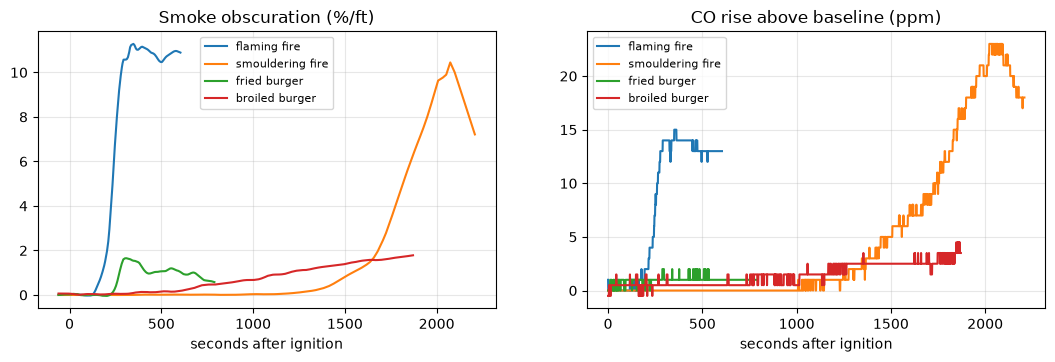

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for name, lab in [('FFoamG1T1', 'flaming fire'), ('SFoamG1T1', 'smouldering fire'), ('FryHBG1T1', 'fried burger'), ('BHBG1T1', 'broiled burger')]:
    x = tests[name]; ax[0].plot(x.t, x.obsc, label=lab); ax[1].plot(x.t, x.co - x.co.dropna().iloc[:10].median(), label=lab)
ax[0].set_title('Smoke obscuration (%/ft)'); ax[1].set_title('CO rise above baseline (ppm)')
for a_ in ax: a_.set_xlabel('seconds after ignition'); a_.legend(fontsize=8)
plt.show()

Smoke rises for **all** sources; CO rises only for the fires.

In [4]:
def first(x, col, th, relative=True):
    # seconds after ignition when col first rises th above its baseline (or reaches th if relative=False)
    if col not in x or x[col].isna().all(): return np.nan
    pre = x.loc[x.t < 0, col].dropna()
    b = pre.median() if len(pre) else x.loc[x.t >= 0, col].dropna().iloc[:10].median()   # gas analysers start at ignition
    hit = x[(x.t >= 0) & ((x[col] - (b if relative else 0)) >= th)]
    return hit.t.iloc[0] if len(hit) else np.nan
rows = []
for name, x in tests.items():
    rows.append({'source': SRC[re.match('[A-Za-z]+?(?=G)', name).group()],
                 'smoke >= 1 %/ft': first(x, 'obsc', 1.0, relative=False), 'CO +10 ppm': first(x, 'co', 10),
                 'ceiling T +5 °C': first(x, 'tc1', 5), 'CO2 +0.05 %': first(x, 'co2', .05)})
r = pd.DataFrame(rows)
def cell(s): return f"{s.notna().sum()}/{len(s)}" + (f", {s.median():.0f} s" if s.notna().any() else '')
r.groupby('source').agg(cell)

,smoke >= 1 %/ft,CO +10 ppm,ceiling T +5 °C,CO2 +0.05 %
source,,,,
FIRE flaming,"15/15, 185 s","15/15, 270 s","15/15, 262 s","15/15, 218 s"
FIRE smouldering,"15/15, 1340 s","15/15, 1550 s","1/15, 1969 s","2/15, 1220 s"
broiled burger,"15/15, 1230 s",0/15,"15/15, 944 s",0/15
fried burger,"15/15, 272 s",0/15,0/15,0/15
stir-fry,"15/15, 291 s",0/15,0/15,0/15
toast,0/15,0/15,0/15,0/15


**A CO rise of 10 ppm flags 30/30 real fires and 0/60 cooking tests.** Smoke alone flags cooking too; ceiling temperature is fooled by broiling and misses smouldering fires.

(Toast obscuration in the room files stays low; the summary workbook reports higher values from another measuring point, so treat toast smoke values with care.)

In [5]:
import openpyxl
wb = openpyxl.load_workbook(path('fire/nist-smoke-alarms/summary_nistsmokebox_roomresults.xlsx'), read_only=True, data_only=True)
srcs = ['FIRE flaming', 'FIRE smouldering', 'broiled burger', 'fried burger', 'stir-fry', 'toast']
cnt = {}
for ws in wb.worksheets:
    if not ws.title.startswith('Room'): continue
    tech = re.sub(r'Room\s+', '', ws.title).split('0')[0].rstrip('0123456789')
    for row in ws.iter_rows(values_only=True):
        cells = [v for v in row if v is not None]
        if cells and cells[0] == 'Alarm Time (s)':
            for s, block in zip(srcs, [cells[1:][i:i + 3] for i in range(0, len(cells) - 1, 3)]):
                k = cnt.setdefault((tech, s), [0, 0])
                k[0] += sum(v != 'NA' for v in block); k[1] += len(block)
alarms = pd.Series({k: f"{a}/{n}" for k, (a, n) in cnt.items()}).unstack()[srcs]
alarms.index.name = 'alarm type'; alarms   # I = ionisation, P = photoelectric, PI = dual, ICO/PCO = with CO sensor

,FIRE flaming,FIRE smouldering,broiled burger,fried burger,stir-fry,toast
alarm type,,,,,,
I,42/42,31/42,36/42,15/42,20/42,15/42
ICO,12/12,12/12,9/12,1/12,3/12,3/12
P,39/42,39/42,31/42,38/42,36/42,NaN
PCO,21/21,21/21,19/21,20/21,21/21,NaN
PI,12/12,12/12,12/12,12/12,12/12,3/12
PT,4/6,6/6,3/6,5/6,5/6,NaN


Commercial alarms **sound on cooking** in a large share of tests, often faster than on a smouldering fire: an alarm (or a smoke reading) alone is not a fire.

## 2. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | `fire` = smoke / air quality abnormal **and** (CO ≥ baseline + 10 ppm **or** a fire call). Wait up to ~4 min after smoke for CO. Smoke alone = ambiguous / nuisance (low confidence, no dispatch). CO2 +0.05 % within 1 min also confirms a *flaming* fire |
| **Mock** | Replay three real 1 Hz curves: fire confirmed fast (flaming), fire confirmed slow (smouldering), smoke but no fire (fried burger) |
| **Eval** | Independent fire-vs-nuisance test for the fire rule |
| **Twin hardware** | If the Twin's air-quality sensor has a CO channel (MQ-7 / MQ-9 type), use it; otherwise the fire call is the only second signal |

**Limits:** indoor, single-room lab tests with laboratory analysers; a cheap Twin CO sensor will be noisier and drift.